In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

import sys
import os
from tqdm import tqdm

sys.path.insert(0, os.path.join(os.getcwd(), "..", "scripts"))
from utility_functions import overlap, true_not_predicted, predicted_not_true, charge, \
    make_tada_intervals, make_paddle_intervals, make_adhunter_intervals, not_predicted_not_true, AD_coords, \
    make_adhunter_ensemble_intervals, make_adpred_intervals

In [2]:
color_dict = {
    'TADA' : 'green',
    'ADpred' : 'dodgerblue',
    'ADhunterEnsemble' : 'red', 
    'ADhunterLite' : 'orange',
    'Paddle' : 'purple'
}

In [3]:
# Read in predictions from individual predictors
individual_predictions = pd.read_csv('arnold_seqs_with_ADs_combined_all_six.csv',
                                     index_col=0, 
                                     converters={'combined_preds' : ast.literal_eval, 
                                                })

# Convert to lists of tuples
individual_predictions['adhunter_intervals'] = individual_predictions['adhunter_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_centers'] = individual_predictions['adhunter_centers'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_preds'] = individual_predictions['adhunter_preds'].fillna('[]').apply(ast.literal_eval)


individual_predictions['tada_intervals'] = individual_predictions['tada_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['tada_centers'] = individual_predictions['tada_centers'].fillna('[]').apply(ast.literal_eval)
individual_predictions['tada_preds'] = individual_predictions['tada_preds'].fillna('[]').apply(ast.literal_eval)

individual_predictions['adpred_intervals'] = individual_predictions['adpred_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adpred_preds'] = individual_predictions['adpred_preds'].fillna('[]').apply(ast.literal_eval)

individual_predictions['paddle_intervals'] = individual_predictions['paddle_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['paddle_centers'] = individual_predictions['paddle_centers'].apply(ast.literal_eval)
individual_predictions['paddle_preds'] = individual_predictions['paddle_preds'].apply(ast.literal_eval)

individual_predictions['adhunter_ensemble_intervals'] = individual_predictions['adhunter_ensemble_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_ensemble_preds'] = individual_predictions['adhunter_ensemble_preds'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_ensemble_centers'] = individual_predictions['adhunter_ensemble_centers'].fillna('[]').apply(ast.literal_eval)

individual_predictions['composition_intervals'] = individual_predictions['composition_intervals'].fillna('[]').apply(ast.literal_eval)

In [4]:
# individual_predictions
# individual_predictions['ae_length'] = [len(ls) for ls in individual_predictions['adhunter_ensemble_preds']]
# individual_predictions['p_length'] = [len(ls) for ls in individual_predictions['paddle_preds']]
# individual_predictions['seq_length'] = [len(ls) for ls in individual_predictions['sequence']]
# individual_predictions['combined_length'] = [len(ls) for ls in individual_predictions['combined_preds']]

# individual_predictions[['ae_length', 'p_length', 'combined_length', 'seq_length']]

# individual_predictions['adhunter_ensemble_preds'] = [ls[:l] for l, ls in zip(individual_predictions['p_length'], individual_predictions['adhunter_ensemble_preds'])]
# individual_predictions['adhunter_ensemble_centers'] = [ls[:l] for l, ls in zip(individual_predictions['p_length'], individual_predictions['adhunter_ensemble_centers'])]

In [5]:
# Read in parrot model predictions
with open('arnold_seqs_consensus_all_six_preds.tsv', 'r') as f:
    lines = f.readlines()

names = []
seqs = []
pred_ls = []

for line in lines: 
    line = line.split()
    name = line[0]
    seq = line[1]
    preds = line[2:]
    preds = [float(p) for p in preds]
    names.append(name)
    seqs.append(seq)
    pred_ls.append(preds)

consensus_preds = pd.DataFrame({'name' : names, 'sequence' : seqs, 'preds' : pred_ls})
consensus_preds['name'] = consensus_preds['name'].str.replace(">", "")

In [6]:
# consensus_names = consensus_preds['name']

# Read in experimental data
data = pd.read_csv('arnold_seqs_with_short_ADs.csv', index_col=0)
data['ad_charge'] = data['sequence'].apply(charge)
data['start'] = (data["start tAD [relative to TF CDS]"] / 3).astype(int)
data['end'] = (data["end tAD [relative to TF CDS]"] / 3).astype(int)

# Checking that indicies work how we expect
for i in data.index:
    print(data.loc[i, 'tAD sequence [aa]'] == data.loc[i, 'protein_seq'][data.loc[i, 'start']:data.loc[i, 'end']])

# Make it so that each row is a protein (instead of each row is an AD)
data = (
    data.assign(real_AD_coords=list(zip(data["start"], data["end"])))
        .groupby(["TF_name", 'protein_seq'], as_index=False)["real_AD_coords"]
        .agg(list)
)
data = data.rename(columns={'TF_name' : 'name', 'protein_seq' : 'sequence'})

merged_individual = individual_predictions.merge(data, on=['name', 'sequence'], how='right')
merged_consensus = consensus_preds.merge(data, on=['name', 'sequence'], how='right') 

True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True


In [7]:
# Merge predictions
merged_individual = individual_predictions.merge(data, on=['name', 'sequence'], how='right')
merged_consensus = consensus_preds.merge(data, on=['name', 'sequence'], how='right') 


# Doing it the easy way

In [8]:
merged_consensus

,name,sequence,preds,real_AD_coords
0,Bteb2_FBtr0070735,MDFFATGGFQQLYSDLEEEPLAGGDALLNIVSVGEFDSTYVDTSFS...,"[0.6225795, 0.64430994, 0.5879901, 0.5935061, ...","[(64, 157)]"
1,CG10321_FBtr0071660,MDRKKVLELDKICRLCISERKEMRPLFSEKVPEMLMDCTSVRVEPT...,"[-0.042648423, -0.036972333, -0.024285365, -0....","[(716, 778)]"
2,CG13287_FBtr0077027,MNLLMDSMPSHANPGQRRPTPPQHAELRISTSPQQSPQQNQTTNHN...,"[0.023475163, 0.03472997, 0.011572133, -0.0145...","[(272, 444)]"
3,CG14451_FBtr0078538,MENRRCTVVAVGDLVDELGFCCEWCGKVYKSLVRYHNHIVCTHKLP...,"[0.16041979, 0.17354545, 0.14955525, 0.1437678...","[(194, 264)]"
4,CG1620_FBtr0300830,MMEFGKSSDHSQHSASEASADSGSLANSDLAVTPTKRERRKSPATS...,"[0.00064803567, -0.023091067, -0.016547255, -0...","[(293, 389)]"
5,CG16778_FBtr0100126,MLKDAHQKLIKHRQSTKLSMTDFACQAAPVKQPLPLELPLPLSVQL...,"[-0.039760757, -0.059650872, -0.032340597, -0....","[(796, 886)]"
6,CG17186_FBtr0083858,MSQTCQRTETLTIEALDFIYEDEMEYLHLKQAPRKEEQVKAVKIKR...,"[0.3153481, 0.34453955, 0.34989598, 0.34587467...","[(276, 367)]"
7,CG30020_FBtr0088235,MALNKRKSPYSDPISGAEVDYKLSCRCCLKTNVEYVKLDSVSVARS...,"[-0.03911869, -0.034027543, -0.0510281, -0.037...","[(1103, 1227), (598, 677)]"
8,CG30431_FBtr0085991,MLSLLPHHPLVCRCCLLEQPPLYHSLYDASSQLAVELKALAPALRL...,"[-0.009774701, -0.029782072, -0.014658314, -0....","[(190, 298)]"
9,CG3726_FBtr0070858,MLPQQYCLRWKYHHSNLQTMFSQLLDRGCFCDVTLACEGQLIRAHR...,"[-0.006368247, -0.023875844, -0.007897829, 0.0...","[(271, 355)]"


In [9]:
merged_individual['ae_length'] = [len(ls) for ls in merged_individual['adhunter_ensemble_preds']]
merged_individual['p_length'] = [len(ls) for ls in merged_individual['paddle_preds']]
merged_individual['seq_length'] = [len(ls) for ls in merged_individual['sequence']]

In [10]:
len(merged_individual.loc[7, 'adhunter_ensemble_centers'])

1257

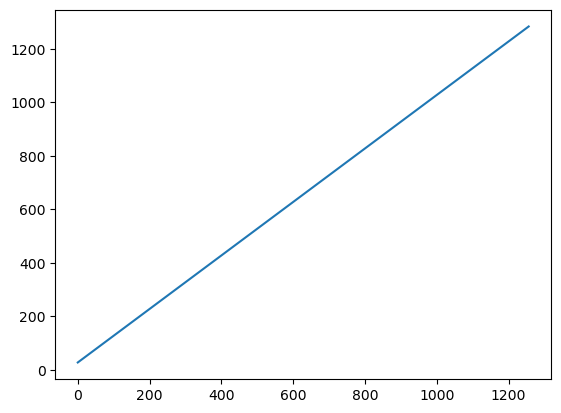

In [11]:
# For some reason it repeats twice (repeat sequences?)
plt.plot(merged_individual.loc[7, 'adhunter_ensemble_centers'])

In [12]:
len(merged_individual.loc[7, 'paddle_centers'])

1257

In [13]:
merged_individual.loc[7, 'adhunter_ensemble_preds']

[-0.5867519378662109,
 -0.672972559928894,
 -0.7262743711471558,
 -0.5439237952232361,
 -0.5369695425033569,
 -0.2103104144334793,
 -0.060608722269535065,
 -0.1265886127948761,
 -0.12895725667476654,
 -0.08643409609794617,
 -0.025812368839979172,
 0.157953679561615,
 -0.12054053694009781,
 -0.3128783404827118,
 -0.4414668083190918,
 -0.5935910940170288,
 -0.5996242761611938,
 -0.6016427278518677,
 -0.6968056559562683,
 -0.6608064770698547,
 -0.715546190738678,
 -0.7086633443832397,
 -0.6627322435379028,
 -0.5832384824752808,
 -0.5378345847129822,
 -0.479652464389801,
 -0.4352489411830902,
 -0.4192054867744446,
 -0.5130805373191833,
 -0.4511459767818451,
 -0.4294249415397644,
 -0.643963098526001,
 -0.5680310130119324,
 -0.5836032629013062,
 -0.5748979449272156,
 -0.49735015630722046,
 -0.47583693265914917,
 -0.47265344858169556,
 -0.5321563482284546,
 -0.4415205121040344,
 -0.35700684785842896,
 -0.3622070848941803,
 -0.3510892391204834,
 -0.4034925401210785,
 -0.3539511263370514,
 -0.3

In [14]:
merged_individual[['name', 'ae_length', 'p_length', 'seq_length']]

,name,ae_length,p_length,seq_length
0,Bteb2_FBtr0070735,259,259,311
1,CG10321_FBtr0071660,783,783,835
2,CG13287_FBtr0077027,409,409,461
3,CG14451_FBtr0078538,212,212,264
4,CG1620_FBtr0300830,405,405,457
5,CG16778_FBtr0100126,994,994,1046
6,CG17186_FBtr0083858,329,329,381
7,CG30020_FBtr0088235,1257,1257,1309
8,CG30431_FBtr0085991,366,366,418
9,CG3726_FBtr0070858,624,624,676


In [15]:
tada_pred_ls = []
adhunterlite_pred_ls = []
parrot_ls = []
real_ls = []
paddle_ls = []
adhunterensemble_ls = []
adpred_ls = []

# Note: We are treating each tile as a single prediction at the tile center
# Is that fair??

for i in merged_individual.index: 
    if len(merged_individual.loc[i, 'sequence']) < 53:
        continue
    # Add padding to predictions (Not exactly what's going on when we call intervals)
    tada_pred_ls += [merged_individual.loc[i, 'tada_preds'][0]] * 20 + \
                list(merged_individual.loc[i, 'tada_preds']) + \
                    [merged_individual.loc[i, 'tada_preds'][-1]] * 19 
    
    adhunterlite_pred_ls += [merged_individual.loc[i, 'adhunter_preds'][0]] * 20 + \
                list(merged_individual.loc[i, 'adhunter_preds']) + \
                    [merged_individual.loc[i, 'adhunter_preds'][-1]] * 19 
    
    # Check PADDLE coords
    paddle_ls += [merged_individual.loc[i, 'paddle_preds'][0]] * 27 + \
                list(merged_individual.loc[i, 'paddle_preds']) + \
                    [merged_individual.loc[i, 'paddle_preds'][-1]] * 25
    
    adhunterensemble_ls += [merged_individual.loc[i, 'adhunter_ensemble_preds'][0]] * 27 + \
                list(merged_individual.loc[i, 'adhunter_ensemble_preds']) + \
                    [merged_individual.loc[i, 'adhunter_ensemble_preds'][-1]] * 25
    
    real = [0] * len(merged_consensus.loc[i, 'sequence'])
    for start, end in merged_consensus.loc[i, 'real_AD_coords']: 
        real[start:end] = [1] * (end-start)

    parrot_ls += list(merged_consensus.loc[i, 'preds'])
    adpred_ls += list(merged_individual.loc[i, 'adpred_preds'])
    
    real_ls += real
    

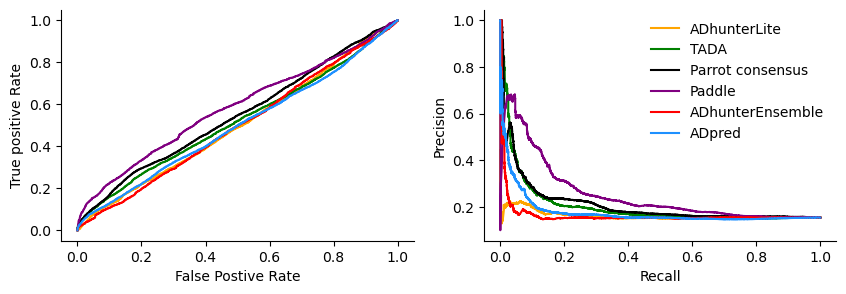

In [16]:
from sklearn.metrics import roc_curve, precision_recall_curve

fig, axs = plt.subplots(1, 2, figsize=(10, 3))

adhunterlite_fpr, adhunterlite_tpr, _ = roc_curve(real_ls, adhunterlite_pred_ls)
tada_fpr, tada_tpr, _ = roc_curve(real_ls, tada_pred_ls)
parrot_fpr, parrot_tpr, _ = roc_curve(real_ls, parrot_ls)
paddle_fpr, paddle_tpr, _ = roc_curve(real_ls, paddle_ls)
adhunter_e_fpr, adhunter_e_tpr, _ = roc_curve(real_ls, adhunterensemble_ls)
adpred_fpr, adpred_tpr, _ = roc_curve(real_ls, adpred_ls)

adhunterlite_prec, adhunterlite_rec, adhunterlite_thresh = precision_recall_curve(real_ls, adhunterlite_pred_ls)
tada_prec, tada_rec, tada_thresh = precision_recall_curve(real_ls, tada_pred_ls)
parrot_prec, parrot_rec, parrot_thresh = precision_recall_curve(real_ls, parrot_ls)
paddle_prec, paddle_rec, paddle_thresh = precision_recall_curve(real_ls, paddle_ls)
adhunter_e_prec, adhunter_e_rec, adhunter_e_thresh = precision_recall_curve(real_ls, adhunterensemble_ls)
adpred_prec, adpred_rec, adpred_thresh = precision_recall_curve(real_ls, adpred_ls)

axs[0].plot(adhunterlite_fpr, adhunterlite_tpr, label='ADhunterLite', color = color_dict['ADhunterLite'])
axs[0].plot(tada_fpr, tada_tpr, label='TADA', color = color_dict['TADA'])
axs[0].plot(parrot_fpr, parrot_tpr, label='Parrot consensus', color = 'black')
axs[0].plot(paddle_fpr, paddle_tpr, label='Paddle', color = color_dict['Paddle'])
axs[0].plot(adhunter_e_fpr, adhunter_e_tpr, label='ADhunterEnsemble', color = color_dict['ADhunterEnsemble'])
axs[0].plot(adpred_fpr, adpred_tpr, label='ADpred', color = color_dict['ADpred'])
axs[0].set_xlabel("False Postive Rate")
axs[0].set_ylabel("True positive Rate")

axs[1].plot(adhunterlite_rec, adhunterlite_prec,  label='ADhunterLite', color = color_dict['ADhunterLite'])
axs[1].plot(tada_rec, tada_prec, label='TADA', color = color_dict['TADA'])
axs[1].plot(parrot_rec, parrot_prec, label='Parrot consensus', color='black')
axs[1].plot(paddle_rec, paddle_prec, label='Paddle', color = color_dict['Paddle'])
axs[1].plot(adhunter_e_rec, adhunter_e_prec, label='ADhunterEnsemble', color = color_dict['ADhunterEnsemble'])
axs[1].plot(adpred_rec, adpred_prec, label='ADpred', color = color_dict['ADpred'])
axs[1].set_xlabel("Recall")
axs[1].set_ylabel("Precision")

axs[1].legend(frameon=False)

sns.despine()

# Doing it the hard way

In [17]:
# All true positives
tp = overlap(merged_individual.loc[0], ad_coords_col='tada_intervals')
fp = predicted_not_true(merged_individual.loc[0], ad_coords_col='tada_intervals')
fn = true_not_predicted(merged_individual.loc[0], ad_coords_col='tada_intervals')

In [18]:
precision = tp / (tp + fp)
precision

0.5740740740740741

In [19]:
recall = tp / (tp + fn)
recall

1.0

In [ ]:
# Beacuse the threshold biases the F1 score so much, I think PRC curves are a better choice

def calculate_precision_recall_tada(threshold):
    intervals = make_tada_intervals(individual_predictions, threshold)
    if intervals is None: # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))

    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['TADA'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_paddle(threshold):
    intervals = make_paddle_intervals(individual_predictions, threshold)
    if intervals is None: # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))
    
    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['PADDLE'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_adhunterlite(threshold):
    intervals = make_adhunter_intervals(individual_predictions, threshold)
    if intervals is None: # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))

    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['ADHunter'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_adhunterensemble(threshold):
    intervals = make_adhunter_ensemble_intervals(individual_predictions, threshold)
    if intervals is None: # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))

    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['ADHunter_ensemble'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_adpred(threshold):
    intervals = make_adpred_intervals(individual_predictions, threshold)
    if (intervals is None) or (len(intervals) == 0): # If there are NO regions with activation doamins
        return 0, 1, 0, 0
    
    intervals["Start"] = intervals["Start"].astype(int)
    intervals["End"] = intervals["End"].astype(int)
    # intervals = intervals.groupby(['name', 'predictor']).apply(lambda x: list(zip(x['Start'], x['End']))).unstack('predictor')
    intervals = (intervals.groupby(['name', 'predictor'])[['Start', 'End']]
                .apply(lambda x: list(zip(x['Start'], x['End'])))
                .unstack('predictor'))

    merged = intervals.merge(data, on='name', how='right')
    merged['intervals'] = merged['ADPred'].apply(lambda x: x if isinstance(x, list) else [])
    
    tp = merged.apply(overlap, ad_coords_col='intervals', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='intervals', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='intervals', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='intervals', axis=1).sum()

    r = tp / (tp + fn)
    p = tp / (tp + fp)

    tpr = tp / (tp + fn) # This is the same as recall
    fpr = fp / (fp + tn)

    return r, p, fpr, tpr

def calculate_precision_recall_parrot(threshold):
    consensus_preds['predicted_AD_coords'] = consensus_preds['preds'].apply(AD_coords, threshold=threshold)

    merged = consensus_preds.merge(data, on=['name', 'sequence'], how='right')
    tp = merged.apply(overlap, ad_coords_col='predicted_AD_coords', axis=1).sum()
    fp = merged.apply(predicted_not_true, ad_coords_col='predicted_AD_coords', axis=1).sum()
    fn = merged.apply(true_not_predicted, ad_coords_col='predicted_AD_coords', axis=1).sum()
    tn = merged.apply(not_predicted_not_true, ad_coords_col='predicted_AD_coords', axis=1).sum()

    parrot_r = tp / (tp + fn)
    parrot_p = tp / (tp + fp)

    parrot_tpr = tp / (tp + fn) # This is the same as recall
    parrot_fpr = fp / (fp + tn)

    return parrot_r, parrot_p, parrot_fpr, parrot_tpr



In [27]:
calculate_precision_recall_adpred(threshold)

(0, 1, 0, 0)

In [21]:
# protein_length-52 -1 is the final tile start

In [22]:
adhunter_e_recalls = []
adhunter_e_precisions = []
adhunter_e_fpr = []
adhunter_e_tpr = []

for threshold in tqdm(adhunter_e_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_adhunterensemble(threshold)
    adhunter_e_recalls.append(r)
    adhunter_e_precisions.append(p)    
    adhunter_e_fpr.append(fpr)
    adhunter_e_tpr.append(tpr)

  0%|          | 6/31186 [00:00<19:36, 26.51it/s]

100%|██████████| 31186/31186 [12:58<00:00, 40.04it/s]   


In [30]:
adpred_recalls = []
adpred_precisions = []
adpred_fpr = []
adpred_tpr = []

for threshold in tqdm(adpred_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_adpred(threshold)
    adpred_recalls.append(r)
    adpred_precisions.append(p)    
    adpred_fpr.append(fpr)
    adpred_tpr.append(tpr)

100%|██████████| 33744/33744 [08:41<00:00, 64.71it/s] 


In [31]:
adhunter_l_recalls = []
adhunter_l_precisions = []
adhunter_l_fpr = []
adhunter_l_tpr = []

for threshold in tqdm(adhunterlite_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_adhunterlite(threshold)
    adhunter_l_recalls.append(r)
    adhunter_l_precisions.append(p)    
    adhunter_l_fpr.append(fpr)
    adhunter_l_tpr.append(tpr)

100%|██████████| 31817/31817 [13:56<00:00, 38.03it/s]


In [32]:
paddle_recalls = []
paddle_precisions = []
paddle_fpr = []
paddle_tpr = []

for threshold in tqdm(paddle_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_paddle(threshold)
    paddle_recalls.append(r)
    paddle_precisions.append(p)    
    paddle_fpr.append(fpr)
    paddle_tpr.append(tpr)

100%|██████████| 31209/31209 [17:24<00:00, 29.88it/s]


In [33]:
tada_recalls = []
tada_precisions = []
tada_fpr = []
tada_tpr = []

for threshold in tqdm(tada_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_tada(threshold)
    tada_recalls.append(r)
    tada_precisions.append(p)    
    tada_fpr.append(fpr)
    tada_tpr.append(tpr)

100%|██████████| 31745/31745 [14:23<00:00, 36.75it/s]


In [34]:
parrot_recalls = []
parrot_precisions = []
parrot_fpr = []
parrot_tpr = []

for threshold in tqdm(parrot_thresh[::]):
    r, p, fpr, tpr = calculate_precision_recall_parrot(threshold)
    parrot_recalls.append(r)
    parrot_precisions.append(p)    
    parrot_fpr.append(fpr)
    parrot_tpr.append(tpr)

100%|█████████▉| 33708/33725 [03:34<00:00, 260.38it/s]/var/folders/34/1pw3__x51kdfyh3vk72f5vc80000gn/T/ipykernel_3729/2667785484.py:153: RuntimeWarning: invalid value encountered in scalar divide
  parrot_p = tp / (tp + fp)
/var/folders/34/1pw3__x51kdfyh3vk72f5vc80000gn/T/ipykernel_3729/2667785484.py:153: RuntimeWarning: invalid value encountered in scalar divide
  parrot_p = tp / (tp + fp)
/var/folders/34/1pw3__x51kdfyh3vk72f5vc80000gn/T/ipykernel_3729/2667785484.py:153: RuntimeWarning: invalid value encountered in scalar divide
  parrot_p = tp / (tp + fp)
/var/folders/34/1pw3__x51kdfyh3vk72f5vc80000gn/T/ipykernel_3729/2667785484.py:153: RuntimeWarning: invalid value encountered in scalar divide
  parrot_p = tp / (tp + fp)
/var/folders/34/1pw3__x51kdfyh3vk72f5vc80000gn/T/ipykernel_3729/2667785484.py:153: RuntimeWarning: invalid value encountered in scalar divide
  parrot_p = tp / (tp + fp)
/var/folders/34/1pw3__x51kdfyh3vk72f5vc80000gn/T/ipykernel_3729/2667785484.py:153: RuntimeWarnin

In [35]:
pd.DataFrame({'parrot_recalls' : parrot_recalls,
              'parrot_precisions' : parrot_precisions,
              'parrot_fpr' : parrot_fpr,
              'parrot_tpr' : parrot_tpr}).to_csv('arnold_parrot_roc_prc_data.csv')

In [36]:
pd.DataFrame({'paddle_recalls' : paddle_recalls,
              'paddle_precisions' : paddle_precisions,
              'paddle_fpr' : paddle_fpr,
              'paddle_tpr' : paddle_tpr}).to_csv('arnold_paddle_roc_prc_data.csv')

In [37]:
pd.DataFrame({'tada_recalls' : tada_recalls,
              'tada_precisions' : tada_precisions,
              'tada_fpr' : tada_fpr,
              'tada_tpr' : tada_tpr}).to_csv('arnold_tada_roc_prc_data.csv')

In [38]:
pd.DataFrame({'adpred_recalls' : adpred_recalls,
              'adpred_precisions' : adpred_precisions,
              'adpred_fpr' : adpred_fpr,
              'adpred_tpr' : adpred_tpr}).to_csv('arnold_adpred_roc_prc_data.csv')
            

In [39]:
pd.DataFrame({'adhunter_l_recalls' : adhunter_l_recalls,
              'adhunter_l_precisions' : adhunter_l_precisions,
              'adhunter_l_fpr' : adhunter_l_fpr,
              'adhunter_l_tpr' : adhunter_l_tpr}).to_csv('arnold_adhunter_l_roc_prc_data.csv')

In [40]:
pd.DataFrame({'adhunter_e_recalls' : adhunter_e_recalls,
              'adhunter_e_precisions' : adhunter_e_precisions,
              'adhunter_e_fpr' : adhunter_e_fpr,
              'adhunter_e_tpr' : adhunter_e_tpr}).to_csv('arnold_adhunter_e_roc_prc_data.csv')

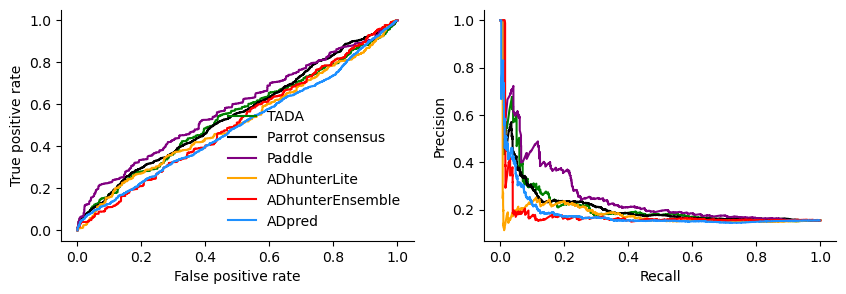

In [41]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3))

axs[0].plot(tada_fpr, tada_tpr, label='TADA', color=color_dict['TADA'])
axs[0].plot(parrot_fpr, parrot_tpr, label='Parrot consensus', color='black')
axs[0].plot(paddle_fpr, paddle_tpr, label='Paddle', color=color_dict['Paddle'])
axs[0].plot(adhunter_l_fpr, adhunter_l_tpr, label='ADhunterLite', color=color_dict['ADhunterLite'])
axs[0].plot(adhunter_e_fpr, adhunter_e_tpr, label='ADhunterEnsemble', color=color_dict['ADhunterEnsemble'])
axs[0].plot(adpred_fpr, adpred_tpr, label='ADpred', color=color_dict['ADpred'])
axs[0].set_xlabel("False positive rate")
axs[0].set_ylabel("True positive rate")
axs[0].legend(frameon=False)

axs[1].plot(tada_recalls, tada_precisions, label='TADA', color=color_dict['TADA'])
axs[1].plot(parrot_recalls, parrot_precisions, label='Parrot consensus', color='black')
axs[1].plot(paddle_recalls, paddle_precisions, label='Paddle', color=color_dict['Paddle']) 
axs[1].plot(adhunter_l_recalls, adhunter_l_precisions, label='ADhunterLite', color=color_dict['ADhunterLite'])
axs[1].plot(adhunter_e_recalls, adhunter_e_precisions, label='ADhunterEnsemble', color=color_dict['ADhunterEnsemble'])
axs[1].plot(adpred_recalls, adpred_precisions, label='ADpred', color=color_dict['ADpred'])
axs[1].set_xlabel("Recall")
axs[1].set_ylabel("Precision")

sns.despine()

plt.savefig("Arf_ROC_PRC.png", format='png')
plt.savefig("Arf_ROC_PRC.pdf", format='pdf')

In [42]:
from sklearn.metrics import auc

print(f"TADA PRC AUC: {auc(tada_recalls, tada_precisions):.3}")
print(f"Parrot consensus PRC AUC: {auc(parrot_recalls, parrot_precisions):.3}")
print(f"Paddle PRC AUC: {auc(paddle_recalls, paddle_precisions):.3}")
print(f"ADhunterLite PRC AUC: {auc(adhunter_l_recalls, adhunter_l_precisions):.3}")
print(f"ADhunterEnsemble PRC AUC: {auc(adhunter_e_recalls, adhunter_e_precisions):.3}")
print(f"ADpred PRC AUC: {auc(adpred_recalls, adpred_precisions):.3}")

TADA PRC AUC: 0.216
Parrot consensus PRC AUC: nan
Paddle PRC AUC: 0.255
ADhunterLite PRC AUC: 0.18
ADhunterEnsemble PRC AUC: 0.179
ADpred PRC AUC: 0.182


In [43]:
print(f"TADA ROC AUC: {auc(tada_fpr, tada_tpr):.3}")
print(f"Parrot consensus ROC AUC: {auc(parrot_fpr, parrot_tpr):.3}")
print(f"Paddle ROC AUC: {auc(paddle_fpr, paddle_tpr):.3}")
print(f"ADhunterLite ROC AUC: {auc(adhunter_l_fpr, adhunter_l_tpr):.3}")
print(f"ADhunterEnsemble ROC AUC: {auc(adhunter_e_fpr, adhunter_e_tpr):.3}")
print(f"ADpred ROC AUC: {auc(adpred_fpr, adpred_tpr):.3}")

TADA ROC AUC: 0.542
Parrot consensus ROC AUC: 0.552
Paddle ROC AUC: 0.585
ADhunterLite ROC AUC: 0.515
ADhunterEnsemble ROC AUC: 0.511
ADpred ROC AUC: 0.493
